# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
import unicodedata
from random import sample

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score

from scikitplot.metrics import plot_lift_curve

import xgboost as xgb

# Leitura dos Dados

## Produtos

In [2]:
# Produtos
df_produtos = pd.read_csv('./Dados/produto.csv', dtype = {'ID_PRODUTO': str}, sep=',')
print('Shape:', df_produtos.shape)
print('Qtd produtos:', df_produtos.ID_PRODUTO.nunique())
df_produtos = df_produtos.applymap(lambda x: x.strip() if isinstance(x, str) else x)
df_produtos.head()

Shape: (38308, 6)
Qtd produtos: 38308


,ID_PRODUTO,UNIDADE,NIVEL 1,NIVEL 2,NIVEL 3,NIVEL 4
0,0,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
1,1,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
2,2,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
3,3,UN,,,,
4,4,UN,CAES,FARMACIA,DORES E INFECCOES,ANTIBIOTICOS


In [3]:
df_produtos.isna().sum()

ID_PRODUTO    0
UNIDADE       0
NIVEL 1       0
NIVEL 2       0
NIVEL 3       0
NIVEL 4       0
dtype: int64

## Clientes

In [4]:
# Clientes
df_clientes = pd.read_csv('./Dados/cliente.csv', dtype = {'ID_CLIENTE': str}, sep=',')
print('Shape:', df_clientes.shape)
print('Qtd clientes:', df_clientes.ID_CLIENTE.nunique())
df_clientes = df_clientes.applymap(lambda x: x.strip() if isinstance(x, str) else x)
df_clientes = df_clientes.replace('1900/01/01', '')
df_clientes['DATA_NASCIMENTO'] = pd.to_datetime(df_clientes['DATA_NASCIMENTO'], format='%Y/%m/%d', errors='coerce')
df_clientes['PRIMEIRA_COMPRA'] = pd.to_datetime(df_clientes['PRIMEIRA_COMPRA'], format='%Y/%m/%d', errors='coerce')
df_clientes.head()

Shape: (105924, 4)
Qtd clientes: 105924


,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA
0,0,,NaT,2017-03-06
1,1,,NaT,2017-03-06
2,2,,NaT,2017-03-06
3,3,,NaT,2017-02-18
4,4,,NaT,2017-01-16


In [5]:
df_clientes.isna().sum()

ID_CLIENTE             0
SEXO                   0
DATA_NASCIMENTO    60607
PRIMEIRA_COMPRA     4060
dtype: int64

## Vendas

In [6]:
# Venda
df_vendas = pd.read_csv('./Dados/venda.csv',
                        sep=',',
                        decimal = '.',
                        dtype={
                            'ID_CLIENTE': str,
                            'ID_VENDA': str,
                            'ID_PRODUTO': str,
                            'FILIAL': str,
                            'QUANTIDADE': str})
print('Shape:', df_vendas.shape)
print('Qtd vendas:', df_vendas.ID_VENDA.nunique())
print('Qtd clientes:', df_vendas.ID_CLIENTE.nunique())
print('Qtd produtos:', df_vendas.ID_PRODUTO.nunique())
df_vendas = df_vendas.applymap(lambda x: x.strip() if isinstance(x, str) else x)
df_vendas['DATA_VENDA'] = pd.to_datetime(df_vendas['DATA_VENDA'], format='%Y/%m/%d', errors='coerce')
df_vendas['QUANTIDADE'] = pd.to_numeric(df_vendas['QUANTIDADE'].str.replace(',', ''))
df_vendas.head()

Shape: (1859583, 7)
Qtd vendas: 854533
Qtd clientes: 89535
Qtd produtos: 21804


,ID_VENDA,DATA_VENDA,ID_CLIENTE,ID_PRODUTO,QUANTIDADE,CATEGORIA_VENDA,FILIAL
0,0,2021-02-10,45659,17631,1.0,E-COMMERCE,101
1,0,2021-02-10,45659,34575,1.0,E-COMMERCE,101
2,1,2021-02-12,70766,2240,1.0,E-COMMERCE,101
3,2,2021-02-12,42579,17707,1.0,E-COMMERCE,101
4,2,2021-02-12,42579,8952,1.0,E-COMMERCE,101


In [7]:
df_vendas.isna().sum()

ID_VENDA                0
DATA_VENDA              0
ID_CLIENTE         929866
ID_PRODUTO              0
QUANTIDADE              0
CATEGORIA_VENDA         0
FILIAL                  0
dtype: int64

# EDA e Feature Engineering

In [8]:
df_vendas_unique = df_vendas.groupby(['ID_VENDA', 'DATA_VENDA', 'ID_CLIENTE', 'CATEGORIA_VENDA']).agg({
    'ID_VENDA': ['count', 'nunique'],
    'QUANTIDADE': ['sum']
}).reset_index()
df_vendas_unique.columns = ['ID_VENDA', 'DATA_VENDA', 'ID_CLIENTE', 'CATEGORIA_VENDA', 'QTD_PRODUTOS', 'QTD_VENDAS', 'SOMA_QTD']
print('Shape:', df_vendas_unique.shape)
df_vendas_unique.head()

Shape: (477013, 7)


,ID_VENDA,DATA_VENDA,ID_CLIENTE,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD
0,0,2021-02-10,45659,E-COMMERCE,2,1,2.0
1,0,2021-02-12,44207,E-COMMERCE,2,1,3.0
2,0,2021-02-27,74218,E-COMMERCE,3,1,3.0
3,0,2021-03-02,72802,E-COMMERCE,1,1,2.0
4,0,2021-03-04,73855,E-COMMERCE,1,1,1.0


In [9]:
df_cliente_vendas = df_clientes.merge(df_vendas_unique, how='left', on='ID_CLIENTE')
print('Shape:', df_cliente_vendas.shape)
df_cliente_vendas.head()

Shape: (493268, 10)


,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD
0,0,,NaT,2017-03-06,NaN,NaT,NaN,NaN,NaN,NaN
1,1,,NaT,2017-03-06,NaN,NaT,NaN,NaN,NaN,NaN
2,2,,NaT,2017-03-06,NaN,NaT,NaN,NaN,NaN,NaN
3,3,,NaT,2017-02-18,NaN,NaT,NaN,NaN,NaN,NaN
4,4,,NaT,2017-01-16,NaN,NaT,NaN,NaN,NaN,NaN


In [10]:
print('Qtd clientes SEM venda:', df_cliente_vendas[df_cliente_vendas.ID_VENDA.isnull()].ID_CLIENTE.nunique())
print('Qtd clientes COM venda:', df_cliente_vendas[df_cliente_vendas.ID_VENDA.notnull()].ID_CLIENTE.nunique())

Qtd clientes SEM venda: 17331
Qtd clientes COM venda: 88593


**Clientes sem vendas serão removidos da base**

In [11]:
df_cliente_vendas = df_cliente_vendas[df_cliente_vendas.ID_VENDA.notnull()]
print('Shape:', df_cliente_vendas.shape)
df_cliente_vendas.head()

Shape: (475937, 10)


,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD
7,7,,NaT,2017-03-07,11997,2020-06-15,Estética,1.0,1.0,35.0
8,7,,NaT,2017-03-07,285508,2020-12-11,Clínica,1.0,1.0,160.0
9,7,,NaT,2017-03-07,317729,2020-11-26,Loja,1.0,1.0,1.0
10,7,,NaT,2017-03-07,336134,2021-05-08,Loja,1.0,1.0,1.0
14,11,,NaT,2017-03-07,327271,2021-02-10,Loja,3.0,1.0,3.0


### Quantidade de vendas por cliente

In [12]:
df_qtd_vendas = df_cliente_vendas.groupby('ID_CLIENTE')[['ID_VENDA']].count().reset_index()
df_qtd_vendas = df_qtd_vendas.rename(columns={'ID_VENDA':'QTD_VENDAS'}, inplace=False)
print(df_qtd_vendas.shape)
df_qtd_vendas.head()

(88593, 2)


,ID_CLIENTE,QTD_VENDAS
0,1000,54
1,100000,1
2,100001,3
3,100002,1
4,100003,11


In [13]:
df_qtd_vendas.QTD_VENDAS.value_counts().head(15)

1     29699
2     14561
3      9047
4      6268
5      4766
6      3678
7      2931
8      2378
9      1916
10     1652
11     1462
12     1181
13     1062
14      884
15      758
Name: QTD_VENDAS, dtype: int64

### Tempo entre vendas

In [14]:
print('Última venda:', pd.to_datetime(df_cliente_vendas.DATA_VENDA.max()))
data_ref = pd.to_datetime(df_cliente_vendas.DATA_VENDA.max())

Última venda: 2021-10-26 00:00:00


In [15]:
df_cliente_vendas = df_cliente_vendas.sort_values(['ID_CLIENTE', 'DATA_VENDA'])
df_cliente_vendas = df_cliente_vendas[df_cliente_vendas['DATA_VENDA'] <= data_ref]
print('Shape:', df_cliente_vendas.shape)
df_cliente_vendas['DATA_VENDA_POST'] = df_cliente_vendas.groupby('ID_CLIENTE')['DATA_VENDA'].shift(-1)
df_cliente_vendas['DATA_VENDA_POST'] = df_cliente_vendas['DATA_VENDA_POST'].fillna(data_ref)
df_cliente_vendas.head()

Shape: (475937, 10)


,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD,DATA_VENDA_POST
4657,1000,,NaT,2017-05-21,4449,2020-01-08,Clínica,1.0,1.0,240.0,2020-01-09
4658,1000,,NaT,2017-05-21,4500,2020-01-09,Clínica,1.0,1.0,80.0,2020-04-14
4659,1000,,NaT,2017-05-21,46570,2020-04-14,Loja,4.0,1.0,5.0,2020-05-02
4630,1000,,NaT,2017-05-21,10094,2020-05-02,Estética,1.0,1.0,20.0,2020-05-07
4660,1000,,NaT,2017-05-21,48324,2020-05-07,Loja,5.0,1.0,11.0,2020-06-15


In [16]:
df_cliente_vendas['TEMPO_ENTRE_VENDAS'] = (df_cliente_vendas['DATA_VENDA_POST'] - df_cliente_vendas['DATA_VENDA']).dt.days
df_cliente_vendas.head()

,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD,DATA_VENDA_POST,TEMPO_ENTRE_VENDAS
4657,1000,,NaT,2017-05-21,4449,2020-01-08,Clínica,1.0,1.0,240.0,2020-01-09,1
4658,1000,,NaT,2017-05-21,4500,2020-01-09,Clínica,1.0,1.0,80.0,2020-04-14,96
4659,1000,,NaT,2017-05-21,46570,2020-04-14,Loja,4.0,1.0,5.0,2020-05-02,18
4630,1000,,NaT,2017-05-21,10094,2020-05-02,Estética,1.0,1.0,20.0,2020-05-07,5
4660,1000,,NaT,2017-05-21,48324,2020-05-07,Loja,5.0,1.0,11.0,2020-06-15,39


In [17]:
df_tempo_entre_vendas = df_cliente_vendas.groupby('TEMPO_ENTRE_VENDAS')[['ID_VENDA']].count().reset_index()
df_tempo_entre_vendas = df_tempo_entre_vendas.rename(columns={'ID_VENDA':'QTD_VENDAS'}, inplace=False)
print(df_tempo_entre_vendas.shape)
df_tempo_entre_vendas.head(15)

(664, 2)


,TEMPO_ENTRE_VENDAS,QTD_VENDAS
0,0,43708
1,1,14538
2,2,11154
3,3,11021
4,4,10812
5,5,10641
6,6,11356
7,7,16728
8,8,10427
9,9,9077


# Construção da Base de Modelagem

In [18]:
df_cliente_vendas.DATA_VENDA.dt.strftime('%Y%m').sort_values(ascending=False).value_counts(sort=False)

202110    29766
202109    36898
202108    37158
202107    37192
202106    35573
202105    33709
202104    30819
202103    30568
202102    28241
202101    29628
202012    28660
202011    23445
202010    19269
202009    16211
202008    15063
202007    10007
202006     6647
202005     6509
202004     4472
202003     5071
202002     5379
202001     5652
Name: DATA_VENDA, dtype: int64

## Mês exemplo

### Definição da data de referência

In [19]:
anomes_ref = '202107'
dias_churn = 90
data_ref = pd.to_datetime(anomes_ref, format='%Y%m')
data_lim_resp = data_ref + timedelta(days=dias_churn)
data_lim_cart = data_ref + timedelta(days=-dias_churn)
print('Data ref:', data_ref)
print('Data limite resposta:', data_lim_resp)
print('Data limite carteira:', data_lim_cart)

Data ref: 2021-07-01 00:00:00
Data limite resposta: 2021-09-29 00:00:00
Data limite carteira: 2021-04-02 00:00:00


In [20]:
df_cliente_vendas.head()

,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD,DATA_VENDA_POST,TEMPO_ENTRE_VENDAS
4657,1000,,NaT,2017-05-21,4449,2020-01-08,Clínica,1.0,1.0,240.0,2020-01-09,1
4658,1000,,NaT,2017-05-21,4500,2020-01-09,Clínica,1.0,1.0,80.0,2020-04-14,96
4659,1000,,NaT,2017-05-21,46570,2020-04-14,Loja,4.0,1.0,5.0,2020-05-02,18
4630,1000,,NaT,2017-05-21,10094,2020-05-02,Estética,1.0,1.0,20.0,2020-05-07,5
4660,1000,,NaT,2017-05-21,48324,2020-05-07,Loja,5.0,1.0,11.0,2020-06-15,39


### Seleção da carteira (clientes com compras nos 90 dias anteriores à data referência)

In [21]:
# Seleção da carteira (clientes com compras nos 90 dias anteriores à data referência)
df_clientes_cart = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] >= data_lim_cart) &
                                     (df_cliente_vendas['DATA_VENDA'] < data_ref)]\
    .groupby('ID_CLIENTE')[['DATA_VENDA']].max().reset_index()
df_clientes_cart = df_clientes_cart.rename(columns={'DATA_VENDA':'ULTIMA_VENDA'})
print('Tamanho carteira:', df_clientes_cart.shape)
df_clientes_cart.head()

Tamanho carteira: (38728, 2)


,ID_CLIENTE,ULTIMA_VENDA
0,1000,2021-06-15
1,10005,2021-06-07
2,10007,2021-06-20
3,10008,2021-05-23
4,10010,2021-06-26


### Seleção das compras nos 90 dias posteriores à data referência para marcação do churn

In [22]:
# Seleção das compras nos 90 dias posteriores à data referência para marcação do churn
df_clientes_prox_venda = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] >= data_ref) &
                                           (df_cliente_vendas['DATA_VENDA'] < data_lim_resp)].\
    groupby('ID_CLIENTE')[['DATA_VENDA']].min().reset_index()
df_clientes_prox_venda = df_clientes_prox_venda.rename(columns={'DATA_VENDA':'PROXIMA_VENDA'})
df_clientes_prox_venda['DATA_REF'] = data_ref
df_clientes_prox_venda['DATA_PROX_MES'] = df_clientes_prox_venda['DATA_REF'] + pd.DateOffset(months=1)
data_prox_mes = df_clientes_prox_venda['DATA_PROX_MES'].max()
print('Data prox mês:', data_prox_mes)
df_clientes_prox_venda['PROX_VENDA_AJUST'] = df_clientes_prox_venda[['PROXIMA_VENDA','DATA_PROX_MES']].min(axis=1)
print('Shape:', df_clientes_prox_venda.shape)
df_clientes_prox_venda.head()

Data prox mês: 2021-08-01 00:00:00
Shape: (42771, 5)


,ID_CLIENTE,PROXIMA_VENDA,DATA_REF,DATA_PROX_MES,PROX_VENDA_AJUST
0,1000,2021-07-12,2021-07-01,2021-08-01,2021-07-12
1,100000,2021-09-11,2021-07-01,2021-08-01,2021-08-01
2,100001,2021-09-11,2021-07-01,2021-08-01,2021-08-01
3,100002,2021-09-11,2021-07-01,2021-08-01,2021-08-01
4,100003,2021-09-11,2021-07-01,2021-08-01,2021-08-01


### Criação da marcação de churn com a verificação do tempo entre a última compra anterior à data de referência e a primeira compra posterior à mesma

In [23]:
# Criação da marcação de churn com a verificação do tempo entre a última compra anterior à data de referência e a primeira compra posterior à mesma
df_clientes_cart_resp = df_clientes_cart.merge(df_clientes_prox_venda, on='ID_CLIENTE', how='left')
print('Shape:', df_clientes_cart_resp.shape)
df_clientes_cart_resp['DIAS_PROX_VENDA'] = (df_clientes_cart_resp['PROXIMA_VENDA'] - df_clientes_cart_resp['ULTIMA_VENDA']).dt.days
df_clientes_cart_resp['PROX_VENDA_AJUST'] = df_clientes_cart_resp['PROX_VENDA_AJUST'].fillna(data_prox_mes)
df_clientes_cart_resp['DIAS_PROX_VENDA_AJUST'] = (df_clientes_cart_resp['PROX_VENDA_AJUST'] - df_clientes_cart_resp['ULTIMA_VENDA']).dt.days
df_clientes_cart_resp['FLAG_CHURN'] = np.where(df_clientes_cart_resp['DIAS_PROX_VENDA'] < dias_churn, 0, 1)
df_clientes_cart_resp['FLAG_CHURN_MES'] = np.where(df_clientes_cart_resp['DIAS_PROX_VENDA_AJUST'] < dias_churn, 0, 1)
print(df_clientes_cart_resp.FLAG_CHURN.value_counts())
df_clientes_cart_resp.head()

Shape: (38728, 6)
1    19596
0    19132
Name: FLAG_CHURN, dtype: int64


,ID_CLIENTE,ULTIMA_VENDA,PROXIMA_VENDA,DATA_REF,DATA_PROX_MES,PROX_VENDA_AJUST,DIAS_PROX_VENDA,DIAS_PROX_VENDA_AJUST,FLAG_CHURN,FLAG_CHURN_MES
0,1000,2021-06-15,2021-07-12,2021-07-01,2021-08-01,2021-07-12,27.0,27,0,0
1,10005,2021-06-07,2021-07-18,2021-07-01,2021-08-01,2021-07-18,41.0,41,0,0
2,10007,2021-06-20,2021-07-15,2021-07-01,2021-08-01,2021-07-15,25.0,25,0,0
3,10008,2021-05-23,NaT,NaT,NaT,2021-08-01,NaN,70,1,0
4,10010,2021-06-26,NaT,NaT,NaT,2021-08-01,NaN,36,1,0


### Criação das features apenas com as vendas anteriores à data referência

In [24]:
# Criação das features apenas com as vendas anteriores à data referência
df_vendas_feat = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] < data_ref) & 
                                   (df_cliente_vendas['ID_CLIENTE'].isin(df_clientes_cart.ID_CLIENTE.unique().tolist()))]
print('Shape:', df_vendas_feat.shape)
df_vendas_feat.head()

Shape: (254512, 12)


,ID_CLIENTE,SEXO,DATA_NASCIMENTO,PRIMEIRA_COMPRA,ID_VENDA,DATA_VENDA,CATEGORIA_VENDA,QTD_PRODUTOS,QTD_VENDAS,SOMA_QTD,DATA_VENDA_POST,TEMPO_ENTRE_VENDAS
4657,1000,,NaT,2017-05-21,4449,2020-01-08,Clínica,1.0,1.0,240.0,2020-01-09,1
4658,1000,,NaT,2017-05-21,4500,2020-01-09,Clínica,1.0,1.0,80.0,2020-04-14,96
4659,1000,,NaT,2017-05-21,46570,2020-04-14,Loja,4.0,1.0,5.0,2020-05-02,18
4630,1000,,NaT,2017-05-21,10094,2020-05-02,Estética,1.0,1.0,20.0,2020-05-07,5
4660,1000,,NaT,2017-05-21,48324,2020-05-07,Loja,5.0,1.0,11.0,2020-06-15,39


In [25]:
# Agrupa por cliente para criação das features
df_clientes_feat = df_vendas_feat.groupby(['ID_CLIENTE']).agg({'QTD_VENDAS':'sum',
                                                               'QTD_PRODUTOS':'sum',
                                                               'SOMA_QTD':'sum',
                                                               'DATA_VENDA':['min', 'max'],
                                                               'DATA_NASCIMENTO':'max'}).reset_index()
df_clientes_feat.columns = ['ID_CLIENTE', 'QTD_VENDAS', 'QTD_PRODUTOS', 'SOMA_QTD',
                            'MIN_DATA_VENDA', 'MAX_DATA_VENDA', 'DATA_NASCIMENTO']
print(df_clientes_feat.shape)
df_clientes_feat.head()

(38728, 7)


,ID_CLIENTE,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,MIN_DATA_VENDA,MAX_DATA_VENDA,DATA_NASCIMENTO
0,1000,44.0,115.0,3375.0,2020-01-08,2021-06-15,NaT
1,10005,21.0,30.0,7951.5,2020-02-03,2021-06-07,NaT
2,10007,15.0,35.0,71.0,2020-08-30,2021-06-20,NaT
3,10008,2.0,4.0,4.0,2020-02-14,2021-05-23,NaT
4,10010,8.0,22.0,26.0,2020-05-06,2021-06-26,NaT


In [26]:
# Função para retirada de acento das categorias
def strip_accents(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s)
                   if unicodedata.category(c) != 'Mn')

# Faz pivot para ter quantidade de vendas de cada categoria
df_clientes_feat_cat = pd.pivot_table(df_vendas_feat, values='QTD_VENDAS', index='ID_CLIENTE', columns='CATEGORIA_VENDA', aggfunc='sum', fill_value=0).astype(int)
df_clientes_feat_cat.columns = ['QTD_'+strip_accents(col.replace('-', '')).upper() for col in df_clientes_feat_cat.columns]
df_clientes_feat_cat = df_clientes_feat_cat.reset_index()
print(df_clientes_feat_cat.shape)
df_clientes_feat_cat.head()

(38728, 5)


,ID_CLIENTE,QTD_CLINICA,QTD_ECOMMERCE,QTD_ESTETICA,QTD_LOJA
0,1000,8,0,8,28
1,10005,12,0,1,8
2,10007,0,0,0,15
3,10008,0,0,0,2
4,10010,0,0,0,8


In [27]:
df_features = df_clientes_feat.merge(df_clientes_feat_cat, on='ID_CLIENTE', how='left')
print(df_features.shape)
df_features.head()

(38728, 11)


,ID_CLIENTE,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,MIN_DATA_VENDA,MAX_DATA_VENDA,DATA_NASCIMENTO,QTD_CLINICA,QTD_ECOMMERCE,QTD_ESTETICA,QTD_LOJA
0,1000,44.0,115.0,3375.0,2020-01-08,2021-06-15,NaT,8,0,8,28
1,10005,21.0,30.0,7951.5,2020-02-03,2021-06-07,NaT,12,0,1,8
2,10007,15.0,35.0,71.0,2020-08-30,2021-06-20,NaT,0,0,0,15
3,10008,2.0,4.0,4.0,2020-02-14,2021-05-23,NaT,0,0,0,2
4,10010,8.0,22.0,26.0,2020-05-06,2021-06-26,NaT,0,0,0,8


In [28]:
# Calcula demais features
df_features['DATA_REF'] = data_ref
df_features['IDADE'] = df_features['DATA_REF'].dt.year - df_features['DATA_NASCIMENTO'].dt.year
df_features['TEMPO_DE_CASA'] = (df_features['DATA_REF'] - df_features['MIN_DATA_VENDA']) / np.timedelta64(1, 'D')
df_features['TEMPO_ENTRE_VENDAS'] = (df_features['MAX_DATA_VENDA'] - df_features['MIN_DATA_VENDA']) / np.timedelta64(1, 'D')
df_features['FREQUENCIA'] = (df_features['TEMPO_ENTRE_VENDAS'] / df_features['QTD_VENDAS'])
df_features['RECENCIA'] = (df_features['DATA_REF'] - df_features['MAX_DATA_VENDA']) / np.timedelta64(1, 'D')
df_features = df_features.drop(['MIN_DATA_VENDA', 'MAX_DATA_VENDA', 'DATA_NASCIMENTO', 'IDADE'], axis=1)
print(df_features.shape)
df_features.head()

(38728, 13)


,ID_CLIENTE,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ECOMMERCE,QTD_ESTETICA,QTD_LOJA,DATA_REF,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA
0,1000,44.0,115.0,3375.0,8,0,8,28,2021-07-01,540.0,524.0,11.909091,16.0
1,10005,21.0,30.0,7951.5,12,0,1,8,2021-07-01,514.0,490.0,23.333333,24.0
2,10007,15.0,35.0,71.0,0,0,0,15,2021-07-01,305.0,294.0,19.600000,11.0
3,10008,2.0,4.0,4.0,0,0,0,2,2021-07-01,503.0,464.0,232.000000,39.0
4,10010,8.0,22.0,26.0,0,0,0,8,2021-07-01,421.0,416.0,52.000000,5.0


In [29]:
# Junta base final de modelagem
df_modelo = df_features.merge(df_clientes_cart_resp[['ID_CLIENTE', 'FLAG_CHURN', 'FLAG_CHURN_MES']], on='ID_CLIENTE', how='left')
print(df_modelo.shape)
df_modelo.head()

(38728, 15)


,ID_CLIENTE,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ECOMMERCE,QTD_ESTETICA,QTD_LOJA,DATA_REF,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES
0,1000,44.0,115.0,3375.0,8,0,8,28,2021-07-01,540.0,524.0,11.909091,16.0,0,0
1,10005,21.0,30.0,7951.5,12,0,1,8,2021-07-01,514.0,490.0,23.333333,24.0,0,0
2,10007,15.0,35.0,71.0,0,0,0,15,2021-07-01,305.0,294.0,19.600000,11.0,0,0
3,10008,2.0,4.0,4.0,0,0,0,2,2021-07-01,503.0,464.0,232.000000,39.0,1,0
4,10010,8.0,22.0,26.0,0,0,0,8,2021-07-01,421.0,416.0,52.000000,5.0,1,0


## Loop de construção da base em diversas referências

In [30]:
lista_anomes_ref = ['202101', '202102', '202103', '202104', '202105', '202106', '202107']
dias_churn = 90
print(lista_anomes_ref)

['202101', '202102', '202103', '202104', '202105', '202106', '202107']


In [31]:
def constroi_base_modelagem(anomes_ref):
    # definição dos datas de referência
    data_ref = pd.to_datetime(anomes_ref, format='%Y%m')
    data_lim_resp = data_ref + timedelta(days=dias_churn)
    data_lim_cart = data_ref + timedelta(days=-dias_churn)
    print('Data ref:', data_ref)
    
    # Seleção da carteira (clientes com compras nos 90 dias anteriores à data referência)
    df_clientes_cart = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] >= data_lim_cart) &
                                         (df_cliente_vendas['DATA_VENDA'] < data_ref)]\
        .groupby('ID_CLIENTE')[['DATA_VENDA']].max().reset_index()
    df_clientes_cart = df_clientes_cart.rename(columns={'DATA_VENDA':'ULTIMA_VENDA'})
    
    # Seleção das compras nos 90 dias posteriores à data referência para marcação do churn
    df_clientes_prox_venda = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] >= data_ref) &
                                               (df_cliente_vendas['DATA_VENDA'] < data_lim_resp)].\
        groupby('ID_CLIENTE')[['DATA_VENDA']].min().reset_index()
    df_clientes_prox_venda = df_clientes_prox_venda.rename(columns={'DATA_VENDA':'PROXIMA_VENDA'})
    df_clientes_prox_venda['DATA_REF'] = data_ref
    df_clientes_prox_venda['DATA_PROX_MES'] = df_clientes_prox_venda['DATA_REF'] + pd.DateOffset(months=1)
    data_prox_mes = df_clientes_prox_venda['DATA_PROX_MES'].max()
    df_clientes_prox_venda['PROX_VENDA_AJUST'] = df_clientes_prox_venda[['PROXIMA_VENDA','DATA_PROX_MES']].min(axis=1)
    
    # Criação da marcação de churn com a verificação do tempo entre a última compra anterior à data de referência e a primeira compra posterior à mesma
    df_clientes_cart_resp = df_clientes_cart.merge(df_clientes_prox_venda, on='ID_CLIENTE', how='left')
    df_clientes_cart_resp['DIAS_PROX_VENDA'] = (df_clientes_cart_resp['PROXIMA_VENDA'] - df_clientes_cart_resp['ULTIMA_VENDA']).dt.days
    df_clientes_cart_resp['PROX_VENDA_AJUST'] = df_clientes_cart_resp['PROX_VENDA_AJUST'].fillna(data_prox_mes)
    df_clientes_cart_resp['DIAS_PROX_VENDA_AJUST'] = (df_clientes_cart_resp['PROX_VENDA_AJUST'] - df_clientes_cart_resp['ULTIMA_VENDA']).dt.days
    df_clientes_cart_resp['FLAG_CHURN'] = np.where(df_clientes_cart_resp['DIAS_PROX_VENDA'] < dias_churn, 0, 1)
    df_clientes_cart_resp['FLAG_CHURN_MES'] = np.where(df_clientes_cart_resp['DIAS_PROX_VENDA_AJUST'] < dias_churn, 0, 1)
    
    # Criação das features apenas com as vendas anteriores à data referência
    df_vendas_feat = df_cliente_vendas[(df_cliente_vendas['DATA_VENDA'] < data_ref) & 
                                       (df_cliente_vendas['ID_CLIENTE'].isin(df_clientes_cart.ID_CLIENTE.unique().tolist()))]
    
    # Agrupa por cliente para criação das features
    df_clientes_feat = df_vendas_feat.groupby(['ID_CLIENTE']).agg({'QTD_VENDAS':'sum',
                                                                   'QTD_PRODUTOS':'sum',
                                                                   'SOMA_QTD':'sum',
                                                                   'DATA_VENDA':['min', 'max'],
                                                                   'DATA_NASCIMENTO':'max'}).reset_index()
    df_clientes_feat.columns = ['ID_CLIENTE', 'QTD_VENDAS', 'QTD_PRODUTOS', 'SOMA_QTD',
                                'MIN_DATA_VENDA', 'MAX_DATA_VENDA', 'DATA_NASCIMENTO']
    
    # Faz pivot para ter quantidade de vendas de cada categoria
    df_clientes_feat_cat = pd.pivot_table(df_vendas_feat, values='QTD_VENDAS', index='ID_CLIENTE', columns='CATEGORIA_VENDA', aggfunc='sum', fill_value=0).astype(int)
    df_clientes_feat_cat.columns = ['QTD_'+strip_accents(col.replace('-', '')).upper() for col in df_clientes_feat_cat.columns]
    df_clientes_feat_cat = df_clientes_feat_cat.reset_index()
    df_features = df_clientes_feat.merge(df_clientes_feat_cat, on='ID_CLIENTE', how='left')
    
    # Calcula demais features
    df_features['DATA_REF'] = data_ref
    df_features['IDADE'] = df_features['DATA_REF'].dt.year - df_features['DATA_NASCIMENTO'].dt.year
    df_features['TEMPO_DE_CASA'] = (df_features['DATA_REF'] - df_features['MIN_DATA_VENDA']) / np.timedelta64(1, 'D')
    df_features['TEMPO_ENTRE_VENDAS'] = (df_features['MAX_DATA_VENDA'] - df_features['MIN_DATA_VENDA']) / np.timedelta64(1, 'D')
    df_features['FREQUENCIA'] = (df_features['TEMPO_ENTRE_VENDAS'] / df_features['QTD_VENDAS'])
    df_features['RECENCIA'] = (df_features['DATA_REF'] - df_features['MAX_DATA_VENDA']) / np.timedelta64(1, 'D')
    df_features = df_features.drop(['MIN_DATA_VENDA', 'MAX_DATA_VENDA', 'DATA_NASCIMENTO', 'IDADE'], axis=1)
    
    # Junta base final de modelagem
    df_modelo = df_features.merge(df_clientes_cart_resp[['ID_CLIENTE', 'FLAG_CHURN', 'FLAG_CHURN_MES']], on='ID_CLIENTE', how='left')
    return df_modelo

In [32]:
lista_base_modelagem = []

for anomes_ref in lista_anomes_ref:
    
    df_modelo = constroi_base_modelagem(anomes_ref)
    lista_base_modelagem.append(df_modelo)
    
df_modelo_completa = pd.concat(lista_base_modelagem)
print(df_modelo_completa.shape)
df_modelo_completa.head()

Data ref: 2021-01-01 00:00:00
Data ref: 2021-02-01 00:00:00
Data ref: 2021-03-01 00:00:00
Data ref: 2021-04-01 00:00:00
Data ref: 2021-05-01 00:00:00
Data ref: 2021-06-01 00:00:00
Data ref: 2021-07-01 00:00:00
(241259, 15)


,ID_CLIENTE,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,DATA_REF,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES,QTD_ECOMMERCE
0,1000,21.0,50.0,938.7,4,4,13,2021-01-01,359.0,317.0,15.095238,42.0,0,0,NaN
1,10005,13.0,18.0,4657.5,9,1,3,2021-01-01,333.0,295.0,22.692308,38.0,0,0,NaN
2,10007,5.0,10.0,17.0,0,0,5,2021-01-01,124.0,98.0,19.600000,26.0,0,0,NaN
3,10010,5.0,15.0,19.0,0,0,5,2021-01-01,240.0,234.0,46.800000,6.0,0,0,NaN
4,10012,1.0,2.0,2.0,0,0,1,2021-01-01,55.0,0.0,0.000000,55.0,1,0,NaN


In [33]:
df_modelo_completa.isna().sum()

ID_CLIENTE                0
QTD_VENDAS                0
QTD_PRODUTOS              0
SOMA_QTD                  0
QTD_CLINICA               0
QTD_ESTETICA              0
QTD_LOJA                  0
DATA_REF                  0
TEMPO_DE_CASA             0
TEMPO_ENTRE_VENDAS        0
FREQUENCIA                0
RECENCIA                  0
FLAG_CHURN                0
FLAG_CHURN_MES            0
QTD_ECOMMERCE         62392
dtype: int64

In [34]:
df_modelo_completa['QTD_ECOMMERCE'] = df_modelo_completa['QTD_ECOMMERCE'].fillna(0).astype(int)

In [35]:
df_modelo_completa.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 241259 entries, 0 to 38727
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   ID_CLIENTE          241259 non-null  object        
 1   QTD_VENDAS          241259 non-null  float64       
 2   QTD_PRODUTOS        241259 non-null  float64       
 3   SOMA_QTD            241259 non-null  float64       
 4   QTD_CLINICA         241259 non-null  int32         
 5   QTD_ESTETICA        241259 non-null  int32         
 6   QTD_LOJA            241259 non-null  int32         
 7   DATA_REF            241259 non-null  datetime64[ns]
 8   TEMPO_DE_CASA       241259 non-null  float64       
 9   TEMPO_ENTRE_VENDAS  241259 non-null  float64       
 10  FREQUENCIA          241259 non-null  float64       
 11  RECENCIA            241259 non-null  float64       
 12  FLAG_CHURN          241259 non-null  int32         
 13  FLAG_CHURN_MES      241259 non

In [39]:
ordem_cols = df_modelo_completa.columns
print(ordem_cols)

Index(['ID_CLIENTE', 'QTD_VENDAS', 'QTD_PRODUTOS', 'SOMA_QTD', 'QTD_CLINICA',
       'QTD_ESTETICA', 'QTD_LOJA', 'DATA_REF', 'TEMPO_DE_CASA',
       'TEMPO_ENTRE_VENDAS', 'FREQUENCIA', 'RECENCIA', 'FLAG_CHURN',
       'FLAG_CHURN_MES', 'QTD_ECOMMERCE'],
      dtype='object')


## Churn na base de modelagem

### Base completa, churn ilimitado

In [40]:
pd.pivot_table(df_modelo_completa, values='ID_CLIENTE', index='DATA_REF', columns='FLAG_CHURN', aggfunc='count', fill_value=0).astype(int)

FLAG_CHURN,0,1
DATA_REF,,
2021-01-01,14608,15017
2021-02-01,15836,16931
2021-03-01,16330,17975
2021-04-01,16908,17737
2021-05-01,17314,17704
2021-06-01,17905,18266
2021-07-01,19132,19596


### Base completa, churn no mês

In [41]:
pd.pivot_table(df_modelo_completa, values='ID_CLIENTE', index='DATA_REF', columns='FLAG_CHURN_MES', aggfunc='count', fill_value=0).astype(int)

FLAG_CHURN_MES,0,1
DATA_REF,,
2021-01-01,25277,4348
2021-02-01,28009,4758
2021-03-01,28123,6182
2021-04-01,28508,6137
2021-05-01,28707,6311
2021-06-01,30270,5901
2021-07-01,32343,6385


### Base de recência >= 60, churn ilimitado

In [42]:
pd.pivot_table(df_modelo_completa[df_modelo_completa['RECENCIA'] >= 60],
               values='ID_CLIENTE', index='DATA_REF', columns='FLAG_CHURN', aggfunc='count', fill_value=0).astype(int)

FLAG_CHURN,0,1
DATA_REF,,
2021-01-01,489,4223
2021-02-01,754,5138
2021-03-01,729,6179
2021-04-01,777,6137
2021-05-01,851,6137
2021-06-01,737,5901
2021-07-01,773,6182


### Base de recência >= 60, churn no mês

In [43]:
pd.pivot_table(df_modelo_completa[df_modelo_completa['RECENCIA'] >= 60],
               values='ID_CLIENTE', index='DATA_REF', columns='FLAG_CHURN_MES', aggfunc='count', fill_value=0).astype(int)

FLAG_CHURN_MES,0,1
DATA_REF,,
2021-01-01,489,4223
2021-02-01,1134,4758
2021-03-01,729,6179
2021-04-01,777,6137
2021-05-01,851,6137
2021-06-01,737,5901
2021-07-01,773,6182


In [44]:
df_modelo_completa = df_modelo_completa.set_index(['ID_CLIENTE', 'DATA_REF'])
df_modelo_completa.head()

,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,,,
1000,2021-01-01,21.0,50.0,938.7,4,4,13,359.0,317.0,15.095238,42.0,0,0,0
10005,2021-01-01,13.0,18.0,4657.5,9,1,3,333.0,295.0,22.692308,38.0,0,0,0
10007,2021-01-01,5.0,10.0,17.0,0,0,5,124.0,98.0,19.600000,26.0,0,0,0
10010,2021-01-01,5.0,15.0,19.0,0,0,5,240.0,234.0,46.800000,6.0,0,0,0
10012,2021-01-01,1.0,2.0,2.0,0,0,1,55.0,0.0,0.000000,55.0,1,0,0


In [45]:
df_modelo_completa = df_modelo_completa[df_modelo_completa['RECENCIA'] >= 60]
print(df_modelo_completa.shape)
df_modelo_completa.head()

(45007, 13)


,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,,,
10030,2021-01-01,2.0,3.0,96.0,1,0,1,266.0,197.0,98.5,69.0,1,1,0
10039,2021-01-01,2.0,2.0,11.0,0,1,1,170.0,90.0,45.0,80.0,1,1,0
10066,2021-01-01,1.0,1.0,1.0,0,0,1,80.0,0.0,0.0,80.0,1,1,0
10073,2021-01-01,1.0,1.0,1.0,0,0,1,65.0,0.0,0.0,65.0,1,1,0
10090,2021-01-01,1.0,1.0,1.0,0,0,1,81.0,0.0,0.0,81.0,1,1,0


# Modelagem

In [46]:
X = df_modelo_completa.drop(['FLAG_CHURN', 'FLAG_CHURN_MES'], axis=1)
print(X.shape)
X.head()

(45007, 11)


,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,
10030,2021-01-01,2.0,3.0,96.0,1,0,1,266.0,197.0,98.5,69.0,0
10039,2021-01-01,2.0,2.0,11.0,0,1,1,170.0,90.0,45.0,80.0,0
10066,2021-01-01,1.0,1.0,1.0,0,0,1,80.0,0.0,0.0,80.0,0
10073,2021-01-01,1.0,1.0,1.0,0,0,1,65.0,0.0,0.0,65.0,0
10090,2021-01-01,1.0,1.0,1.0,0,0,1,81.0,0.0,0.0,81.0,0


In [47]:
y = df_modelo_completa[['FLAG_CHURN']]
print(y.shape)
y.head()

(45007, 1)


,,FLAG_CHURN
ID_CLIENTE,DATA_REF,
10030,2021-01-01,1
10039,2021-01-01,1
10066,2021-01-01,1
10073,2021-01-01,1
10090,2021-01-01,1


## Separação Treino Teste

In [48]:
# Setar seed para obter resultados reproduziveis
seed = 10

# Usar train_test_split para criar o conjunto de teste
X_training, X_test, y_training, y_test = train_test_split(X, y, random_state=seed, test_size=0.25, stratify=y)

print("Test set X", X_test.shape)
print("Test set y", y_test.shape)

Test set X (11252, 11)
Test set y (11252, 1)


In [49]:
# Mesmo procedimento, mas para o conjunto de trieno resultante
X_train, X_val, y_train, y_val = train_test_split(X_training, y_training, random_state=seed,
                                                  test_size=0.33, stratify=y_training)

print("Train set X", X_train.shape)
print("Train set y", y_train.shape)
print("Validation set X", X_val.shape)
print("Validation set y", y_val.shape)

Train set X (22615, 11)
Train set y (22615, 1)
Validation set X (11140, 11)
Validation set y (11140, 1)


## Modelos

In [50]:
def plot_feature_importances(model):
    # Listando features
    n_features = X.shape[1]
    # Gráfico de barras horizontal a partir da importância de cada features
    plt.barh(range(n_features), model.feature_importances_, align='center')
    # Adiciona o ticks, ou traços no eixo Y
    plt.yticks(np.arange(n_features), X.columns)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")
    plt.ylim(-1, n_features)

### Árvore

In [51]:
# Definir os possiveis valores para cada hiperparametro para serem explorados
params = {'max_depth': [2, 3, 4, 5, 6, 7, 8, 9],
          'min_samples_split': [10, 15, 20],
          'min_samples_leaf': [3, 5, 10]}

# Criar objeto com o DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=seed)

# Criar objeto KFold com StratifiedKFold para validação cruzada
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)

# Criar um objeto de grade de busca com GridSearchCV, a partir dos parâmetros que definimos
grid_search = GridSearchCV(tree, param_grid=params, scoring='roc_auc',
                           cv=skf.split(X_training, y_training))

# Treinar o modelo com o grid search
grid_search.fit(X_training, y_training)

# Printar a melhor combinação de hiperparâmetros
print('Melhores hiperparâmetros:')
print(grid_search.best_params_)

Melhores hiperparâmetros:
{'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 10}


Acurácia no conjunto de treino: 0.886
Acurácia no conjunto de validação: 0.886
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1265
           1       0.89      1.00      0.94      9875

    accuracy                           0.89     11140
   macro avg       0.44      0.50      0.47     11140
weighted avg       0.79      0.89      0.83     11140

[[   0 1265]
 [   0 9875]]
Área sob a curva ROC: 0.728


C:\Users\Visagio\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


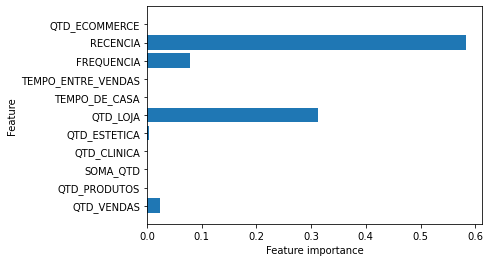

In [52]:
# Gera uma árvore com as melhores combinações de hiperparâmetros
tree = DecisionTreeClassifier(random_state=seed, max_depth=grid_search.best_params_['max_depth'],
                              min_samples_split=grid_search.best_params_['min_samples_split'],
                              min_samples_leaf=grid_search.best_params_['min_samples_leaf'])

# Fita o modelo com o dataset de treino
tree.fit(X_training, y_training)

# Usa o modelo para prever o conjunto de validação
y_val_pred_tree = tree.predict(X_val)
y_val_pred_proba_tree = [x[1] for x in tree.predict_proba(X_val)]

# Calcular e printar métricas
print("Acurácia no conjunto de treino: {:.3f}".format(tree.score(X_train, y_train)))
print("Acurácia no conjunto de validação: {:.3f}".format(tree.score(X_val, y_val)))
print(classification_report(y_val, y_val_pred_tree))
print(confusion_matrix(y_val, y_val_pred_tree))
print("Área sob a curva ROC: {:.3f}".format(roc_auc_score(y_val, y_val_pred_proba_tree)))

# Plotar importância das variáveis
plot_feature_importances(tree)

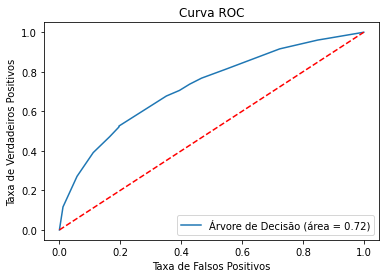

In [53]:
%matplotlib inline

tree_roc_auc = roc_auc_score(y_test, [x[1] for x in tree.predict_proba(X_test)])
fpr, tpr, thresholds = roc_curve(y_test, tree.predict_proba(X_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Árvore de Decisão (área = %0.2f)' % tree_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

### XGBoost


 Melhores hiperparâmetros:
{'alpha': 5, 'colsample_bytree': 0.7, 'learning_rate': 0.3, 'max_depth': 4}
Acurácia média no conjunto de validação: 0.724 +/- 0.004


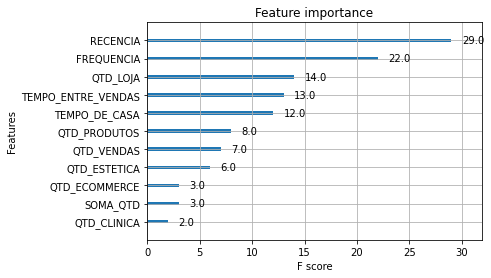

In [54]:
# Define um conjunto de possíveis valores para os hiperparâmetros
params = {'learning_rate': [0.1, 0.2, 0.3],
          'alpha': [5, 10, 15],
          'colsample_bytree': [0.1, 0.3, 0.5, 0.7, 1.0],
          'max_depth': [3, 4, 5]}

# Cria o modelo
xgb_model_cv_gs = xgb.XGBClassifier(objective="binary:logistic", random_state=seed,
                                    eval_metric="auc", n_estimators=10,use_label_encoder=False)

# Cria o grid search com validação cruzada estratificada
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
grid_search = GridSearchCV(xgb_model_cv_gs, param_grid=params, scoring='roc_auc',
                           cv=skf.split(X_training, y_training))

# Treina o modelo e printa os melhores hiperparâmetros
grid_search.fit(X_training, y_training)
print('\n Melhores hiperparâmetros:')
print(grid_search.best_params_)

# Obtém os resultados da validação cruzada
cv_results = pd.DataFrame(grid_search.cv_results_)
print("Acurácia média no conjunto de validação: {:.3f} +/- {:.3f}".format(
  cv_results[cv_results.rank_test_score == 1].mean_test_score.values[0],
  cv_results[cv_results.rank_test_score == 1].std_test_score.values[0])
)

# Atribui os melhores valores para os hiperparâmetros
xgb_model_cv_gs.set_params(learning_rate = grid_search.best_params_['learning_rate'],
                           alpha = grid_search.best_params_['alpha'],
                           colsample_bytree = grid_search.best_params_['colsample_bytree'],
                           max_depth = grid_search.best_params_['max_depth'])

# Treina o modelo usando os melhores hiperparâmetros
xgb_model_cv_gs.fit(X_training, y_training)

# Plota a importância das variáveis
xgb.plot_importance(xgb_model_cv_gs)
plt.show()

In [55]:
# Usa o modelo para prever o conjunto de validação
y_val_pred_xgb = tree.predict(X_val)
y_val_pred_proba_xgb = [x[1] for x in tree.predict_proba(X_val)]

# Calcular e printar métricas
print("Acurácia no conjunto de treino: {:.3f}".format(xgb_model_cv_gs.score(X_train, y_train)))
print("Acurácia no conjunto de validação: {:.3f}".format(xgb_model_cv_gs.score(X_val, y_val)))
print(classification_report(y_val, y_val_pred_xgb))
print(confusion_matrix(y_val, y_val_pred_xgb))
print("Área sob a curva ROC: {:.3f}".format(roc_auc_score(y_val, y_val_pred_proba_xgb)))

Acurácia no conjunto de treino: 0.886
Acurácia no conjunto de validação: 0.886
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1265
           1       0.89      1.00      0.94      9875

    accuracy                           0.89     11140
   macro avg       0.44      0.50      0.47     11140
weighted avg       0.79      0.89      0.83     11140

[[   0 1265]
 [   0 9875]]
Área sob a curva ROC: 0.728


C:\Users\Visagio\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


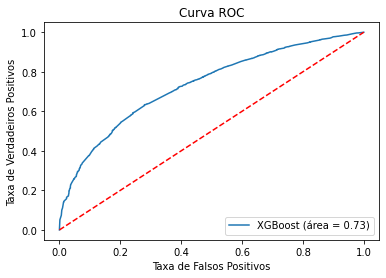

In [56]:
%matplotlib inline

xgb_roc_auc = roc_auc_score(y_test, [x[1] for x in xgb_model_cv_gs.predict_proba(X_test)])
fpr, tpr, thresholds = roc_curve(y_test, xgb_model_cv_gs.predict_proba(X_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='XGBoost (área = %0.2f)' % xgb_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

## Avaliação dos modelos

### AUC

In [57]:
print("AUC Treino Arvore: {:.3f}".format(xgb_roc_auc))
print("AUC Treino XGBoost: {:.3f}".format(tree_roc_auc))
print("AUC Treino Arvore: {:.3f}".format(xgb_roc_auc))
print("AUC Treino XGBoost: {:.3f}".format(tree_roc_auc))

AUC Treino Arvore: 0.733
AUC Treino XGBoost: 0.724
AUC Treino Arvore: 0.733
AUC Treino XGBoost: 0.724


### Precisão

In [58]:
# Realizar as previsões no dataset de teste
y_tree_pred = tree.predict(X_test)
y_xgb_pred = xgb_model_cv_gs.predict(X_test)

# Printar a precisão de cada algoritmo
print(precision_score(y_test, y_tree_pred))
print(precision_score(y_test, y_xgb_pred))

0.8864201919658727
0.8864201919658727


### Lift

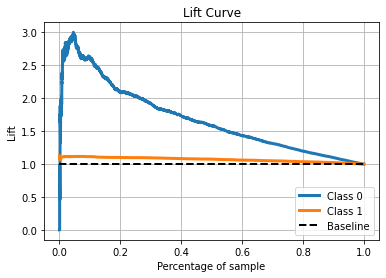

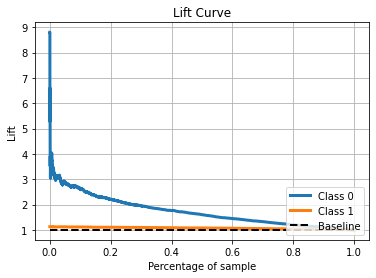

In [59]:
y_tree_proba = tree.predict_proba(X_test)
y_xgb_proba = xgb_model_cv_gs.predict_proba(X_test)

plot_lift_curve(y_test, y_tree_proba)
plot_lift_curve(y_test, y_xgb_proba)
plt.show()

## Base de holdout

In [60]:
anomes_ref_holdout = '202110'

In [61]:
df_holdout = constroi_base_modelagem(anomes_ref)[ordem_cols].set_index(['ID_CLIENTE', 'DATA_REF'])
df_holdout.head()

Data ref: 2021-07-01 00:00:00


,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,,,
1000,2021-07-01,44.0,115.0,3375.0,8,8,28,540.0,524.0,11.909091,16.0,0,0,0
10005,2021-07-01,21.0,30.0,7951.5,12,1,8,514.0,490.0,23.333333,24.0,0,0,0
10007,2021-07-01,15.0,35.0,71.0,0,0,15,305.0,294.0,19.600000,11.0,0,0,0
10008,2021-07-01,2.0,4.0,4.0,0,0,2,503.0,464.0,232.000000,39.0,1,0,0
10010,2021-07-01,8.0,22.0,26.0,0,0,8,421.0,416.0,52.000000,5.0,1,0,0


In [62]:
df_holdout.FLAG_CHURN.value_counts()

1    19596
0    19132
Name: FLAG_CHURN, dtype: int64

In [63]:
df_holdout.FLAG_CHURN_MES.value_counts()

0    32343
1     6385
Name: FLAG_CHURN_MES, dtype: int64

In [64]:
df_holdout = df_holdout[df_holdout['RECENCIA'] >= 60]
print(df_holdout.shape)
df_holdout.head()

(6955, 13)


,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,FLAG_CHURN,FLAG_CHURN_MES,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,,,
10099,2021-07-01,4.0,9.0,19.0,0,1,3,409.0,341.0,85.250000,68.0,1,1,0
10102,2021-07-01,10.0,15.0,795.0,3,0,7,392.0,314.0,31.400000,78.0,1,1,0
10118,2021-07-01,2.0,4.0,4.0,0,0,2,119.0,33.0,16.500000,86.0,1,1,0
10124,2021-07-01,3.0,4.0,4.0,0,0,3,266.0,176.0,58.666667,90.0,1,1,0
10149,2021-07-01,2.0,7.0,7.0,0,0,2,75.0,0.0,0.000000,75.0,1,1,0


In [65]:
df_holdout.FLAG_CHURN.value_counts()

1    6182
0     773
Name: FLAG_CHURN, dtype: int64

In [66]:
df_holdout.FLAG_CHURN_MES.value_counts()

1    6182
0     773
Name: FLAG_CHURN_MES, dtype: int64

In [67]:
X_holdout = df_holdout.drop(['FLAG_CHURN', 'FLAG_CHURN_MES'], axis=1)
print(X_holdout.shape)
X_holdout.head()

(6955, 11)


,,QTD_VENDAS,QTD_PRODUTOS,SOMA_QTD,QTD_CLINICA,QTD_ESTETICA,QTD_LOJA,TEMPO_DE_CASA,TEMPO_ENTRE_VENDAS,FREQUENCIA,RECENCIA,QTD_ECOMMERCE
ID_CLIENTE,DATA_REF,,,,,,,,,,,
10099,2021-07-01,4.0,9.0,19.0,0,1,3,409.0,341.0,85.250000,68.0,0
10102,2021-07-01,10.0,15.0,795.0,3,0,7,392.0,314.0,31.400000,78.0,0
10118,2021-07-01,2.0,4.0,4.0,0,0,2,119.0,33.0,16.500000,86.0,0
10124,2021-07-01,3.0,4.0,4.0,0,0,3,266.0,176.0,58.666667,90.0,0
10149,2021-07-01,2.0,7.0,7.0,0,0,2,75.0,0.0,0.000000,75.0,0


In [68]:
y_holdout = df_holdout[['FLAG_CHURN']]
print(y_holdout.shape)
y_holdout.head()

(6955, 1)


,,FLAG_CHURN
ID_CLIENTE,DATA_REF,
10099,2021-07-01,1
10102,2021-07-01,1
10118,2021-07-01,1
10124,2021-07-01,1
10149,2021-07-01,1


### AUC

In [69]:
# Realizar as previsões no dataset de teste
y_holdout_tree_pred = [x[1] for x in tree.predict_proba(X_holdout)]
y_holdout_xgb_pred = [x[1] for x in xgb_model_cv_gs.predict_proba(X_holdout)]

print("AUC Treino Arvore: {:.3f}".format(roc_auc_score(y_holdout, y_holdout_tree_pred)))
print("AUC Treino XGBoost: {:.3f}".format(roc_auc_score(y_holdout, y_holdout_xgb_pred)))

AUC Treino Arvore: 0.723
AUC Treino XGBoost: 0.736


### Lift

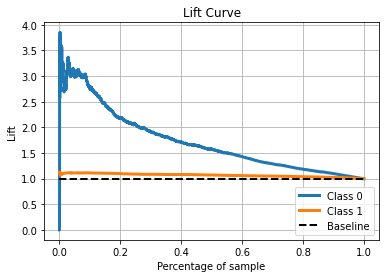

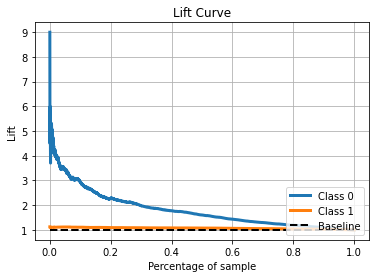

In [70]:
y_holdout_tree_proba = tree.predict_proba(X_holdout)
y_holdout_xgb_proba = xgb_model_cv_gs.predict_proba(X_holdout)

plot_lift_curve(y_holdout, y_holdout_tree_proba)
plot_lift_curve(y_holdout, y_holdout_xgb_proba)
plt.show()

### Dados lift

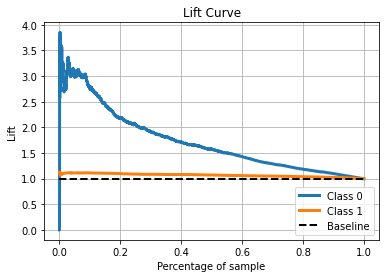

In [71]:
ax = plot_lift_curve(y_holdout, y_holdout_tree_proba)

In [72]:
df_linhas = []
lines = ax.get_lines()[0:-1]
for line in lines:
    xd = line.get_xdata()
    yd = line.get_ydata()
    df_linhas.append(pd.DataFrame({'y':yd}, index=xd))

In [73]:
df_lift = pd.concat(df_linhas, axis=1)
print(df_lift.shape)
df_lift.head()

(6955, 2)


,y,y
0.000144,0.000000,1.12504
0.000288,0.000000,1.12504
0.000431,2.999138,1.12504
0.000575,2.249353,1.12504
0.000719,3.598965,1.12504


In [74]:
df_lift.to_csv('./Dados_Apresentacao/lift_churn.csv', sep=';', decimal=',')